# Population Size and Age Structure Across Hong Kong’s 18 Districts

**Author:** GUO QIZHEN

**Reference year:** 2021

## Research Questions

1. How does age structure differ across Hong Kong’s 18 districts?
2. Do more populous districts also have higher proportions of residents aged 65 and over?

## Data Source

Hong Kong Census and Statistics Department:
2021 Population Census — Statistics by District Council District.

This project describes historical district-level patterns.
It does not represent Hong Kong’s current population structure.

In [2]:
from pathlib import Path

import pandas as pd
from IPython.display import display

DATA_PATH = Path("../data/DC_21C.CSV")

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Cannot find DC_21C.CSV. Check the notebook and data folders."
    )

# The fifth row contains the machine-readable field names.
raw = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    header=4,
    dtype=str
)

print("Raw table shape:", raw.shape)

# Preview the first five records and first sixteen columns.
display(raw.iloc[:5, :16])

Raw table shape: (71, 209)


,dc_class,dc,dc_eng,dc_chi,t_pop,pop_m,pop_f,sr,age_1,age_2,age_3,age_4,age_5,t_ma,ma_m,ma_f
0,A,11,Central and Western,中西區,235953,98282,137671,714,24382,16779,77767,71534,45491,44.8,46.2,43.9
1,B,12,Wan Chai,灣仔區,166695,67075,99620,673,16917,9907,53860,50632,35379,46,48,44.9
2,C,13,Eastern,東區,529603,233542,296061,789,51517,36336,143911,174132,123707,49,49.2,48.8
3,D,14,Southern,南區,263278,116239,147039,791,27255,18842,72397,87976,56808,48.1,48.6,47.7
4,E,27,Yau Tsim Mong,油尖旺區,310647,138873,171774,808,36181,23224,100877,94797,55568,44,45.1,43.2


## Data Preparation and Validation

The source file contains district records, a land-total row, and explanatory notes.
Only the 18 District Council districts are retained for comparison.

Population counts are converted to numeric values. The five age-group counts
are checked against each district's total population.

The analysis covers the 18 land districts. Marine residents are not included.

In [3]:
# Official codes for the 18 District Council districts.
district_codes = [
    "11", "12", "13", "14",
    "23", "24", "25", "26", "27",
    "31", "32", "33", "34", "35",
    "36", "37", "38", "39"
]

column_names = {
    "dc": "district_code",
    "dc_eng": "district",
    "t_pop": "total_population",
    "age_1": "age_0_14",
    "age_2": "age_15_24",
    "age_3": "age_25_44",
    "age_4": "age_45_64",
    "age_5": "age_65_plus"
}

# Keep district records only, without changing the raw table.
districts = raw.loc[
    raw["dc"].isin(district_codes),
    list(column_names)
].copy()

districts = districts.rename(columns=column_names)

age_columns = [
    "age_0_14",
    "age_15_24",
    "age_25_44",
    "age_45_64",
    "age_65_plus"
]

numeric_columns = ["total_population"] + age_columns

for column in numeric_columns:
    districts[column] = pd.to_numeric(
        districts[column],
        errors="raise"
    )

# Validate completeness, uniqueness, and population totals.
assert len(districts) == 18, "Expected exactly 18 districts."
assert districts["district_code"].is_unique, "Duplicate district codes."
assert districts[numeric_columns].notna().all().all(), "Missing counts."
assert (districts[numeric_columns] >= 0).all().all(), "Negative counts."
assert (districts["total_population"] > 0).all(), "Invalid population."

assert districts[age_columns].sum(axis=1).eq(
    districts["total_population"]
).all(), "Age-group counts do not match total population."

districts = districts.reset_index(drop=True)

print("Districts retained:", len(districts))
print("Population validation passed.")

display(districts)

Districts retained: 18
Population validation passed.


,district_code,district,total_population,age_0_14,age_15_24,age_25_44,age_45_64,age_65_plus
0,11,Central and Western,235953,24382,16779,77767,71534,45491
1,12,Wan Chai,166695,16917,9907,53860,50632,35379
2,13,Eastern,529603,51517,36336,143911,174132,123707
3,14,Southern,263278,27255,18842,72397,87976,56808
4,27,Yau Tsim Mong,310647,36181,23224,100877,94797,55568
5,23,Sham Shui Po,431090,49337,35476,123081,135261,87935
6,24,Kowloon City,410634,50327,31113,121174,125562,82458
7,25,Wong Tai Sin,406802,36271,33463,103363,140294,93411
8,26,Kwun Tong,673166,70063,60321,174338,220703,147741
9,31,Kwai Tsing,495798,49421,42474,132936,161501,109466


In [4]:
import numpy as np

# Combine the three middle age groups into ages 15–64.
districts["age_15_64"] = districts[
    ["age_15_24", "age_25_44", "age_45_64"]
].sum(axis=1)

share_columns = [
    "share_0_14",
    "share_15_64",
    "share_65_plus"
]

count_columns = [
    "age_0_14",
    "age_15_64",
    "age_65_plus"
]

for count_column, share_column in zip(count_columns, share_columns):
    districts[share_column] = (
        districts[count_column]
        / districts["total_population"]
        * 100
    )

# Check unrounded percentages before displaying rounded values.
assert np.allclose(
    districts[share_columns].sum(axis=1),
    100
), "Age-group percentages do not sum to 100."

print("Age-group percentage validation passed.")

display(
    districts[
        ["district", "total_population"] + share_columns
    ].round(2)
)

Age-group percentage validation passed.


,district,total_population,share_0_14,share_15_64,share_65_plus
0,Central and Western,235953,10.33,70.39,19.28
1,Wan Chai,166695,10.15,68.63,21.22
2,Eastern,529603,9.73,66.91,23.36
3,Southern,263278,10.35,68.07,21.58
4,Yau Tsim Mong,310647,11.65,70.47,17.89
5,Sham Shui Po,431090,11.44,68.16,20.40
6,Kowloon City,410634,12.26,67.66,20.08
7,Wong Tai Sin,406802,8.92,68.12,22.96
8,Kwun Tong,673166,10.41,67.64,21.95
9,Kwai Tsing,495798,9.97,67.95,22.08


## Figure 1. Age Structure Across Districts

The chart compares the proportions of residents aged 0–14, 15–64,
and 65 and over in each district.

Districts are ordered by the proportion aged 65 and over.
Percentages allow comparison of age structures despite differences
in district population size.

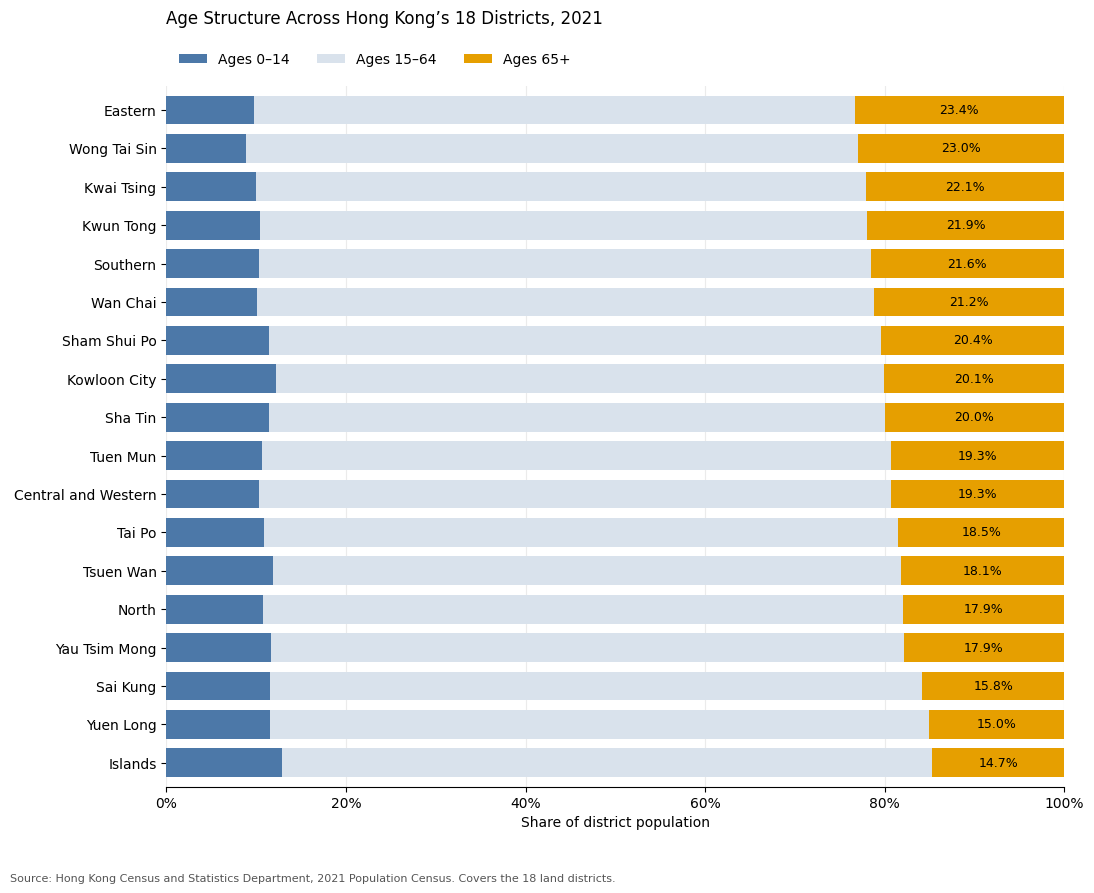

Saved: ../figures/figure01_district_age_structure.png


In [5]:
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(exist_ok=True)

# Highest older-population share appears at the top.
age_plot = (
    districts
    .sort_values("share_65_plus", ascending=False)
    .set_index("district")[share_columns]
    .rename(columns={
        "share_0_14": "Ages 0–14",
        "share_15_64": "Ages 15–64",
        "share_65_plus": "Ages 65+"
    })
)

fig, ax = plt.subplots(figsize=(11, 9))

age_plot.plot.barh(
    stacked=True,
    ax=ax,
    color=["#4C78A8", "#D9E2EC", "#E69F00"],
    width=0.75
)

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlabel("Share of district population")
ax.set_ylabel("")

ax.set_title(
    "Age Structure Across Hong Kong’s 18 Districts, 2021",
    loc="left",
    pad=45
)

ax.legend(
    loc="lower left",
    bbox_to_anchor=(0, 1.01),
    ncol=3,
    frameon=False
)

# Label the older-population segment of every bar.
for position, share in enumerate(age_plot["Ages 65+"]):
    ax.text(
        100 - share / 2,
        position,
        f"{share:.1f}%",
        ha="center",
        va="center",
        fontsize=9
    )

ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)

for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.text(
    0.01,
    0.015,
    "Source: Hong Kong Census and Statistics Department, "
    "2021 Population Census. Covers the 18 land districts.",
    fontsize=8,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.055, 1, 1])

figure_path = FIGURES_DIR / "figure01_district_age_structure.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

print("Saved:", figure_path)

## Figure 2. Population Size and Older-Population Share

This scatter plot compares district population size with the percentage
of residents aged 65 and over.

Each point represents one district. Labels identify the districts with
the highest and lowest population totals and older-population shares.

The dashed line shows the population-weighted older-population share
across the 18 land districts. Any observed association is descriptive
and does not establish causation.

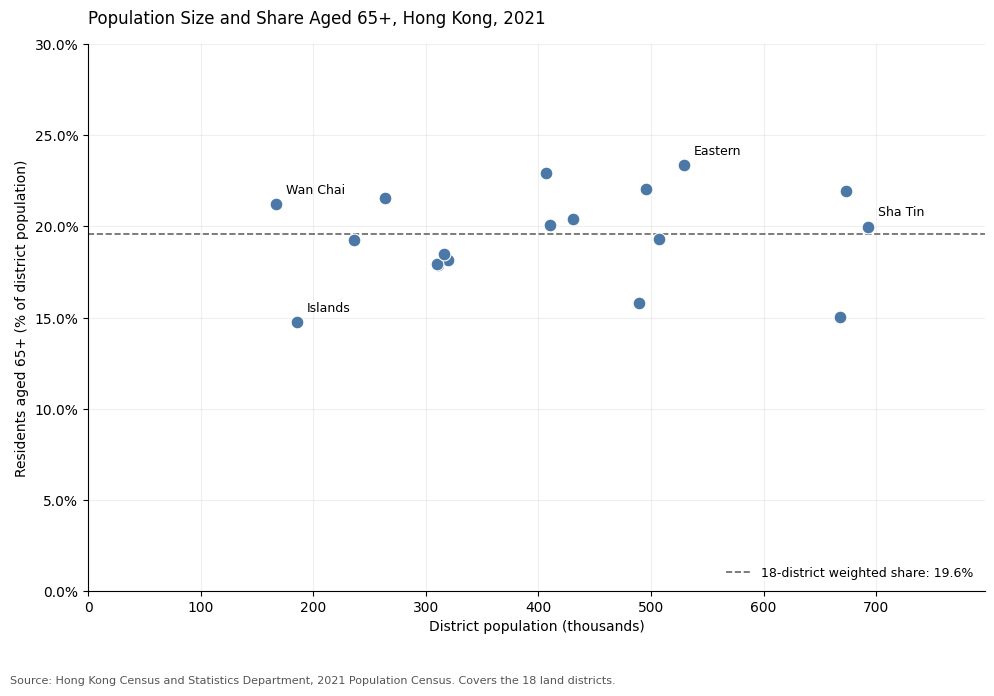

Saved: ../figures/figure02_population_vs_older_share.png
Population-weighted share aged 65+: 19.58%
Pearson correlation across the 18 districts: 0.130


In [6]:
fig, ax = plt.subplots(figsize=(10, 7))

# Express population in thousands for readable axis labels.
population_thousands = districts["total_population"] / 1000

ax.scatter(
    population_thousands,
    districts["share_65_plus"],
    s=85,
    color="#4C78A8",
    edgecolors="white",
    linewidths=0.8,
    zorder=3
)

# Calculate a population-weighted reference, not a simple district average.
weighted_older_share = (
    districts["age_65_plus"].sum()
    / districts["total_population"].sum()
    * 100
)

ax.axhline(
    weighted_older_share,
    color="#666666",
    linestyle="--",
    linewidth=1.2,
    label=f"18-district weighted share: {weighted_older_share:.1f}%"
)

# Label four meaningful extremes without crowding every point.
label_indices = sorted({
    districts["total_population"].idxmax(),
    districts["total_population"].idxmin(),
    districts["share_65_plus"].idxmax(),
    districts["share_65_plus"].idxmin()
})

for index in label_indices:
    row = districts.loc[index]

    ax.annotate(
        row["district"],
        xy=(
            row["total_population"] / 1000,
            row["share_65_plus"]
        ),
        xytext=(7, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Population Size and Share Aged 65+, Hong Kong, 2021",
    loc="left",
    pad=15
)

ax.set_xlabel("District population (thousands)")
ax.set_ylabel("Residents aged 65+ (% of district population)")

ax.set_xlim(0, population_thousands.max() * 1.15)
ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))

ax.set_axisbelow(True)
ax.grid(alpha=0.2)
ax.legend(loc="lower right", frameon=False, fontsize=9)

for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

fig.text(
    0.01,
    0.015,
    "Source: Hong Kong Census and Statistics Department, "
    "2021 Population Census. Covers the 18 land districts.",
    fontsize=8,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.065, 1, 1])

figure_path = FIGURES_DIR / "figure02_population_vs_older_share.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()

correlation = districts["total_population"].corr(
    districts["share_65_plus"]
)

print("Saved:", figure_path)
print(f"Population-weighted share aged 65+: {weighted_older_share:.2f}%")
print(f"Pearson correlation across the 18 districts: {correlation:.3f}")

## Key Findings

1. Age structures differed across Hong Kong’s 18 districts in 2021.
   Eastern had the highest proportion of residents aged 65 and over
   at approximately 23.4%, while Islands had the lowest at 14.7%.

2. Residents aged 65 and over represented 19.58% of the combined
   population of the 18 land districts. This percentage was calculated
   from summed population counts, rather than by averaging district
   percentages equally.

3. No clear linear relationship was observed between district population size and the proportion aged 65 and over across the 18 land districts in 2021 (Pearson r = 0.130). Population size alone provided little indication of the older-population share. This descriptive result does not establish that the variables are unrelated.

## Limitations

- The analysis uses the 2021 Population Census. It does not describe
  Hong Kong's current population structure or establish changes over time.
- The comparison includes 18 land districts and excludes Marine residents.
- District-level summaries hide differences within districts and cannot
  be used to infer individual characteristics.
- Correlation does not establish causation. This analysis does not test
  explanations involving housing, migration, or other demographic factors.

## Conclusion

Population totals and age composition describe different aspects of
a district. Comparing both helps avoid treating a large population
as equivalent to a high older-population share.

A future extension could compare compatible census years or examine
smaller geographical areas, with careful checks of boundary definitions.

## Data Reference

Census and Statistics Department, Hong Kong SAR Government.
2021 Population Census: Statistics by District Council District.

Official dataset:
https://data.gov.hk/en-data/dataset/hk-censtatd-census_geo-2021-population-census-by-dcd

In [7]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])

for package in ["numpy", "pandas", "matplotlib"]:
    print(f"{package}=={version(package)}")

Python: 3.10.22
numpy==1.23.5
pandas==1.5.3
matplotlib==3.7.5
